In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

**1. Data Exploration**

Load the dataset
Inspect variables and identify numeric indicators

In [30]:
# Load dataset
df = pd.read_csv("UN.csv")

# Inspect data
print("Dataset size:", df.shape)
display(df.head())

Dataset size: (207, 14)


,country,region,tfr,contraception,educationMale,educationFemale,lifeMale,lifeFemale,infantMortality,GDPperCapita,economicActivityMale,economicActivityFemale,illiteracyMale,illiteracyFemale
0,Afghanistan,Asia,6.90,NaN,NaN,NaN,45.0,46.0,154.0,2848.0,87.5,7.2,52.800,85.00
1,Albania,Europe,2.60,NaN,NaN,NaN,68.0,74.0,32.0,863.0,NaN,NaN,NaN,NaN
2,Algeria,Africa,3.81,52.0,11.1,9.9,67.5,70.3,44.0,1531.0,76.4,7.8,26.100,51.00
3,American.Samoa,Asia,NaN,NaN,NaN,NaN,68.0,73.0,11.0,NaN,58.8,42.4,0.264,0.36
4,Andorra,Europe,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [31]:
# Identify numeric indicators
numeric_cols = df.select_dtypes(include="number").columns.tolist()
print("Numeric variables:", numeric_cols)

Numeric variables: ['tfr', 'contraception', 'educationMale', 'educationFemale', 'lifeMale', 'lifeFemale', 'infantMortality', 'GDPperCapita', 'economicActivityMale', 'economicActivityFemale', 'illiteracyMale', 'illiteracyFemale']


**2. Missing Vlaues**

Replace missing values with median

In [32]:
# Inspect missing values
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
country                     0
region                      0
tfr                        10
contraception              63
educationMale             131
educationFemale           131
lifeMale                   11
lifeFemale                 11
infantMortality             6
GDPperCapita               10
economicActivityMale       42
economicActivityFemale     42
illiteracyMale             47
illiteracyFemale           47
dtype: int64


In [33]:
# Replace missing values with column medians
df[numeric_cols] = df[numeric_cols].fillna(
    df[numeric_cols].median()
)

# Verify that no missing values remain
print(df[numeric_cols].isnull().sum())

tfr                       0
contraception             0
educationMale             0
educationFemale           0
lifeMale                  0
lifeFemale                0
infantMortality           0
GDPperCapita              0
economicActivityMale      0
economicActivityFemale    0
illiteracyMale            0
illiteracyFemale          0
dtype: int64


**3. Feature Scaling**

Apply a scaling method such as StandardScaler
Briefly explain why scaling is required before clustering

In [34]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(df[numeric_cols])

print("Scaled dataset shape:", X_scaled.shape)

Scaled dataset shape: (207, 12)


**4. Determine the Number of Clusters**

Apply K-Means clustering
Test multiple values of k
Use the Elbow Rule to determine the recommended number of clusters

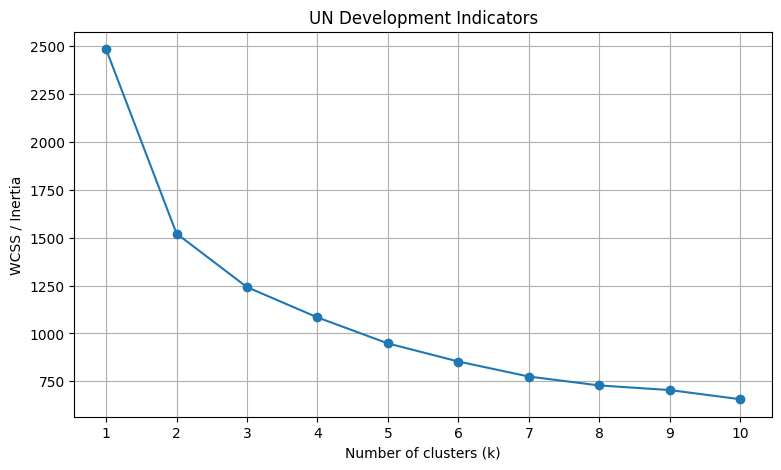

In [35]:
k_values = range(1, 11)
wcss = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(k_values, wcss, marker="o")

plt.xlabel("Number of clusters (k)")
plt.ylabel("WCSS / Inertia")
plt.title("UN Development Indicators")
plt.xticks(list(k_values))
plt.grid(True)

plt.show()

**5. Compare Two Clusters vs Optimal Clusters**

Run clustering with:
k = 2 clusters
k = optimal clusters (from Elbow Rule)

In [36]:
optimal_k = 4

models = {}

for k in sorted(set([2, optimal_k])):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    df[f"cluster_{k}"] = model.fit_predict(X_scaled)
    models[k] = model

    print(f"\nClustering with k = {k}")
    print(df[f"cluster_{k}"].value_counts().sort_index())


Clustering with k = 2
cluster_2
0    143
1     64
Name: count, dtype: int64

Clustering with k = 4
cluster_4
0     26
1     52
2    121
3      8
Name: count, dtype: int64


**6. Evaluate the Results**

  Answer the initial question


In [37]:
indicators = [
    "GDPperCapita",
    "lifeMale",
    "lifeFemale",
    "infantMortality",
    "tfr"
]

print("TWO-CLUSTER MODEL")
print("=================")

# Compare median development indicators
two_cluster_profile = (
    df.groupby("cluster_2")[indicators]
    .median()
    .round(2)
)

display(two_cluster_profile)

# Number of countries in each group
print("\nCountries per cluster:")
print(df["cluster_2"].value_counts())

# Compare performance of the clustering models
print("\nMODEL COMPARISON")

for k, model in models.items():

    explained = 100 * (
        1 - model.inertia_ / wcss[0]
    )

    silhouette = silhouette_score(
        X_scaled, model.labels_
    )

    print(f"\nk = {k}")
    print(f"WCSS reduction: {explained:.2f}%")
    print(f"Silhouette score: {silhouette:.3f}")

TWO-CLUSTER MODEL


,GDPperCapita,lifeMale,lifeFemale,infantMortality,tfr
cluster_2,,,,,
0,2934.0,68.40,74.90,18.0,2.44
1,387.0,51.05,54.25,86.0,5.45



Countries per cluster:
cluster_2
0    143
1     64
Name: count, dtype: int64

MODEL COMPARISON

k = 2
WCSS reduction: 38.75%
Silhouette score: 0.376

k = 4
WCSS reduction: 56.37%
Silhouette score: 0.318


Research Question: **Can the world be meaningfully divided into Developed and Developing countries?**

K-Means clustering with k = 2 identifies two broad groups of countries with different development characteristics. The clusters differ in indicators such as GDP per capita, life expectancy, infant mortality and fertility.

However, the Elbow Method suggests that the optimal number of clusters is 4, rather than two.



**7. Conclusion**

Explain whether the analysis supports the idea that the world cannot be divided into only two groups.


For your final clustering solution, choose one country from each cluster to represent and explain that cluster.

For each selected country, discuss:

Why does this country appear to belong to this cluster?
Does it look similar to the other countries assigned to the same cluster?
What characteristics distinguish this cluster from the others?
Is there anything surprising about the countries grouped together?
Use the countries as concrete examples when presenting your results.

In [38]:
# STEP 7 — REPRESENTATIVE COUNTRIES

# Read original data to check which countries have real data
original = pd.read_csv("UN.csv")

# Count originally available indicators
df["available_indicators"] = (
    original[numeric_cols].notna().sum(axis=1)
)

# Calculate distance from each country to its cluster center
df["distance_to_center"] = np.linalg.norm(
    X_scaled - models[4].cluster_centers_[df["cluster_4"]],
    axis=1
)

# Compare the four clusters
print("CLUSTER CHARACTERISTICS")

profile = df.groupby("cluster_4")[
    ["GDPperCapita", "lifeMale", "lifeFemale",
     "infantMortality", "tfr"]
].median().round(2)

display(profile)

# Choose one representative country per cluster
for cluster in sorted(df["cluster_4"].unique()):

    group = df[df["cluster_4"] == cluster]

    # Prefer countries with enough observed indicators
    candidates = group[group["available_indicators"] >= 8]
    if candidates.empty:
        candidates = group[
            group["available_indicators"] ==
            group["available_indicators"].max()
        ]

    representative = candidates.sort_values(
        "distance_to_center"
    ).iloc[0]

    print(f"\n{'='*45}")
    print(f"CLUSTER {cluster} — {len(group)} countries")
    print(f"REPRESENTATIVE: {representative['country']}")
    print(f"{'='*45}")

    print("\nRepresentative country's indicators:")
    display(representative[
        ["GDPperCapita", "lifeMale", "lifeFemale",
         "infantMortality", "tfr"]
    ])

    print("\nCountries in this cluster:")
    print(", ".join(group["country"].tolist()))

    print("\nCountries closest to the cluster center:")
    print(
        ", ".join(
            group.sort_values("distance_to_center")
            ["country"].head(6).tolist()
        )
    )

CLUSTER CHARACTERISTICS


,GDPperCapita,lifeMale,lifeFemale,infantMortality,tfr
cluster_4,,,,,
0,25836.0,74.55,80.35,6.0,1.64
1,394.0,51.20,54.45,84.5,5.40
2,2305.0,67.50,73.70,23.0,2.77
3,185.0,45.50,48.75,100.5,6.15



CLUSTER 0 — 26 countries
REPRESENTATIVE: Austria

Representative country's indicators:


,10
GDPperCapita,29006.0
lifeMale,73.7
lifeFemale,80.1
infantMortality,6.0
tfr,1.42



Countries in this cluster:
Australia, Austria, Belgium, Canada, Denmark, Finland, France, Germany, Greece, Hong.Kong, Iceland, Ireland, Japan, Korea.Republic.of, Liechtenstein, Luxembourg, Netherlands, New.Zealand, Norway, Portugal, Singapore, Spain, Sweden, Switzerland, United.Kingdom, United.States

Countries closest to the cluster center:
Austria, Belgium, Germany, United.States, Norway, Australia

CLUSTER 1 — 52 countries
REPRESENTATIVE: Comoros

Representative country's indicators:


,38
GDPperCapita,367.0
lifeMale,57.0
lifeFemale,58.0
infantMortality,82.0
tfr,5.51



Countries in this cluster:
Afghanistan, Angola, Bangladesh, Benin, Bhutan, Botswana, Cambodia, Cameroon, Central.African.Rep, Chad, Comoros, Congo, Djibouti, East.Timor, Egypt, Equatorial.Guinea, Ethiopia, Gabon, Ghana, Guatemala, Guinea, Guinea.Bissau, Haiti, India, Iraq, Ivory.Coast, Kenya, Lesotho, Liberia, Madagascar, Malawi, Mali, Mauritania, Morocco, Namibia, Nepal, Niger, Nigeria, Pakistan, Papua.New.Guinea, Rwanda, Senegal, Sierra.Leone, Somalia, Sudan, Swaziland, Tanzania, Togo, Uganda, Vanuatu, Yemen, Zimbabwe

Countries closest to the cluster center:
Comoros, Togo, Bhutan, Tanzania, Ghana, Nigeria

CLUSTER 2 — 121 countries
REPRESENTATIVE: Malaysia

Representative country's indicators:


,114
GDPperCapita,4313.0
lifeMale,69.9
lifeFemale,74.3
infantMortality,11.0
tfr,3.24



Countries in this cluster:
Albania, Algeria, American.Samoa, Andorra, Antigua, Argentina, Armenia, Azerbaijan, Bahamas, Bahrain, Barbados, Belarus, Belize, Bolivia, Bosnia, Brazil, Brunei, Bulgaria, Cape.Verde, Chile, China, Colombia, Cook.Islands, Costa.Rica, Croatia, Cuba, Cyprus, Czech.Republic, Dominica, Dominican.Republic, Ecuador, El.Salvador, Estonia, Fiji, French.Guiana, French.Polynesia, Gaza.Strip, Georgia, Grenada, Guadeloupe, Guam, Guyana, Honduras, Hungary, Indonesia, Iran, Israel, Italy, Jamaica, Jordan, Kazakhstan, Kiribati, Korea.Dem.Peoples.Rep, Kuwait, Kyrgyzstan, Latvia, Lebanon, Libya, Lithuania, Macau, Macedonia, Malaysia, Maldives, Malta, Marshall.Islands, Martinique, Mauritius, Mexico, Micronesia, Moldova, Monaco, Mongolia, Myanmar, Netherlands.Antilles, New.Caledonia, Nicaragua, Northern.Mariana.Islands, Oman, Palau, Panama, Paraguay, Peru, Philippines, Poland, Puerto.Rico, Qatar, Reunion, Romania, Russia, Saint.Kitts, Saint.Lucia, Samoa, San.Marino, Sao.Tome, 

,101
GDPperCapita,359.0
lifeMale,52.0
lifeFemale,55.0
infantMortality,86.0
tfr,6.69



Countries in this cluster:
Burkina.Faso, Burundi, Dem.Rep.of.the.Congo, Eritrea, Gambia, Laos, Mozambique, Zambia

Countries closest to the cluster center:
Laos, Dem.Rep.of.the.Congo, Gambia, Eritrea, Burundi, Zambia


## 7. Conclusion

### Can the World Be Divided into Developed and Developing Countries?

The analysis suggests that dividing countries into only developed and developing categories oversimplifies global development differences. The two-cluster model achieves a WCSS reduction of 38.75%, compared with 56.37% for the four-cluster model. However, the two-cluster model has a higher silhouette score (0.376 vs. 0.318), indicating clearer separation. Thus, four clusters capture more variation, although two clusters remain useful for identifying broad development differences.

### Cluster 1 — High Development (26 Countries)

**Representative country: Austria**

Austria represents this cluster through its high GDP per capita ($29,006), high life expectancy and low infant mortality (6). Its characteristics closely resemble those of Germany, Belgium and Norway. This cluster is distinguished by the highest income and life expectancy indicators. The inclusion of countries from Europe, Asia, North America and Oceania demonstrates that similar development levels occur across different geographical regions.

### Cluster 2 — Lower Development (52 Countries)

**Representative country: Comoros**

Comoros represents this cluster with a GDP per capita of $367, infant mortality of 82 and fertility rate of 5.51. These values closely match the cluster medians and are broadly similar to those of countries such as Togo and Ghana. The cluster is characterized by low incomes, shorter life expectancy and relatively high fertility. The inclusion of geographically diverse countries, such as Afghanistan and Botswana, highlights similarities in development indicators despite different national circumstances.

### Cluster 3 — Intermediate and Mixed Development (121 Countries)

**Representative country: Malaysia**

Malaysia represents this cluster through its intermediate GDP per capita ($4,313), relatively high life expectancy and low infant mortality (11). It shares several development characteristics with countries such as Thailand, China and Brazil. This cluster is distinguished by intermediate and highly varied development indicators. Surprisingly, it also contains countries such as Italy, Qatar and the United Arab Emirates, demonstrating considerable diversity within the largest cluster.

### Cluster 4 — Lowest Development Indicators (8 Countries)

**Representative country: Laos**

Laos represents this cluster through its low GDP per capita ($359), relatively short life expectancy and high fertility rate (6.69). Its characteristics broadly resemble those of Burundi, Mozambique and the Democratic Republic of the Congo. This cluster has the lowest median income and life expectancy, alongside the highest infant mortality and fertility. Notably, Laos is the only Asian country among seven African countries, demonstrating similar development challenges across different regions.

### Final Interpretation — Factfulness

The findings support the broader argument in *Factfulness* that a binary developed/developing classification does not adequately represent global differences. The four-cluster solution reveals distinct development profiles, particularly among countries otherwise classified as developing. However, the relatively diverse composition of Cluster 3 and the higher silhouette score of the two-cluster model indicate that four clusters are not necessarily a definitive classification. Overall, the results suggest that global development is better understood through multiple levels rather than a strict two-group division.